In [6]:
import json
import os
import sys
from pathlib import Path

os.environ["MESA_DIR"] = "/Users/mchau/mesa"   # Replace if your MESA is elsewhere

print("MESA_DIR =", os.environ["MESA_DIR"])

def locate_project_root(start=Path.cwd()):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'tutorial' / 'inlist_project').is_file():
            return candidate
    raise FileNotFoundError('Could not locate tutorial/inlist_project')

PROJECT_ROOT = locate_project_root()
PIPELINE_DIR = PROJECT_ROOT / 'scripts' / 'mams_profiles' / 'pipeline'
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

from mams_pipeline import (
    build_configs, inspect_runs, model_label, prepare_grid,
    render_inlist_project, run_local, submit_slurm,
)

print(f'Project root: {PROJECT_ROOT}')

# Main user-editable parameters
MASSES_MSUN = [5]
INITIAL_Y = 0.2703
INITIAL_Z = 0.0142
STAGE = "RGB"
CENTRAL_H1_LIMIT = 0.01
RGB_RADIUS_LIMIT = 1.6990


# Slurm settings used only if SUBMIT_SLURM is enabled.
PARTITION = 'typhon'
WALLTIME = '7-00:00:00'
CPUS_PER_TASK = 1

# An environment override makes validation and alternate output locations easy.
OUTPUT_ROOT = Path(os.environ.get(
    'MAMS_OUTPUT_ROOT', PROJECT_ROOT / 'results' / 'mams_profiles'
)).resolve()
TEMPLATE_DIR = PROJECT_ROOT / 'tutorial'
OVERWRITE = False
PREPARE_RUNS = True
RUN_LOCAL = True       # Runs models sequentially and waits; potentially slow.
SUBMIT_SLURM = False    # Submits all prepared models and returns job IDs.

if RUN_LOCAL and SUBMIT_SLURM:
    raise ValueError('Choose local execution or Slurm submission, not both.')


configs = build_configs(
    MASSES_MSUN,
    initial_y=INITIAL_Y,
    initial_z=INITIAL_Z,
    central_h1_limit=CENTRAL_H1_LIMIT,
    stage=STAGE,
    rgb_radius_limit=RGB_RADIUS_LIMIT,
    partition=PARTITION,
    walltime=WALLTIME,
    cpus_per_task=CPUS_PER_TASK,
)

for config in configs:
    print(f'{config.mass_msun:8g} M_sun  ->  {model_label(config.stage, config.mass_msun, config.initial_z)}')

template_text = (TEMPLATE_DIR / 'inlist_project').read_text()
preview = render_inlist_project(template_text, configs[0])
keys_to_show = (
    'filename_for_profile_when_terminate', 'save_pulse_data_filename',
    'initial_mass', 'initial_y', 'initial_z', 'Zbase',
    'xa_central_lower_limit(1)', 'rgb_radius_limit',
)
for line in preview.splitlines():
    if any(key in line for key in keys_to_show):
        print(line)

assert f"'{model_label(configs[0].stage, configs[0].mass_msun, configs[0].initial_z)}.profile'" in preview
assert f"'{model_label(configs[0].stage, configs[0].mass_msun, configs[0].initial_z)}.mesa'" in preview
print('In-memory smoke test passed.')

runs = []
if PREPARE_RUNS:
    runs = prepare_grid(
        configs, TEMPLATE_DIR, OUTPUT_ROOT, overwrite=OVERWRITE
    )
    print(f'Prepared {len(runs)} run(s) under {OUTPUT_ROOT}')
else:
    print('PREPARE_RUNS is false; no directories were written.')

inspect_runs(runs)

job_ids = {}
if RUN_LOCAL:
    for run in runs:
        print(f'Running {run.label} ...', flush=True)
        run_local(run)
elif SUBMIT_SLURM:
    for run in runs:
        job_ids[run.label] = submit_slurm(run)
    print(json.dumps(job_ids, indent=2))
else:
    print('Setup only: no MESA processes or Slurm jobs were started.')

status = inspect_runs(runs)
print(json.dumps(status, indent=2))

if runs:
    metadata = json.loads(runs[0].metadata_path.read_text())
    print('\nFirst run metadata:')
    print(json.dumps(metadata, indent=2))

    if runs[0].gyre_path.is_file():
        fields = runs[0].gyre_path.read_text().splitlines()[0].split()
        names = ['zones', 'mass_g', 'radius_cm', 'luminosity_erg_s', 'version']
        print('\nGYRE header:', dict(zip(names, fields)))

MESA_DIR = /Users/mchau/mesa
Project root: /Users/mchau/mesa_tutorial
       5 M_sun  ->  RGB5Msun_Z0p0142
   filename_for_profile_when_terminate = 'RGB5Msun_Z0p0142.profile'
   save_pulse_data_filename = 'RGB5Msun_Z0p0142.mesa'
   initial_mass = 5
   initial_y = 0.2703  ! Helium mass fraction
   initial_z = 0.0142  ! Metal mass fraction, hydrogen = 1 - metal - helium
   xa_central_lower_limit(1) = 0.0
  use_Zbase_for_Type1 = .true.
  Zbase = 0.0142
In-memory smoke test passed.
Prepared 1 run(s) under /Users/mchau/mesa_tutorial/results/mams_profiles
Running RGB5Msun_Z0p0142 ...
[
  {
    "label": "RGB5Msun_Z0p0142",
    "prepared": true,
    "mesa_profile": true,
    "gyre_model": true,
    "run_dir": "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB5Msun_Z0p0142"
  }
]

First run metadata:
{
  "config": {
    "central_h1_limit": 0.01,
    "cpus_per_task": 1,
    "initial_y": 0.2703,
    "initial_z": 0.0142,
    "mass_msun": 5,
    "partition": "typhon",
    "rgb_radius_limit": 1.6

In [9]:
import pandas as pd

file = "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB5Msun_Z0p0142/RGB5Msun_Z0p0142.profile"

profile = pd.read_csv(
    file,
    sep=r"\s+",
    skiprows=5
)

profile.head()

,zone,mass,logR,logT,logRho,logP,x_mass_fraction_H,y_mass_fraction_He,z_mass_fraction_metals,pp,cno,tri_alpha
0,1,5.0,1.709277,3.654341,-8.012162,3.453285,0.7155,0.2703,0.0142,2.820207e-28,0.0,0.0
1,2,5.0,1.709277,3.654341,-8.012162,3.453285,0.7155,0.2703,0.0142,2.820209e-28,0.0,0.0
2,3,5.0,1.709277,3.654341,-8.012161,3.453286,0.7155,0.2703,0.0142,2.820211e-28,0.0,0.0
3,4,5.0,1.709277,3.654341,-8.012161,3.453286,0.7155,0.2703,0.0142,2.820214e-28,0.0,0.0
4,5,5.0,1.709277,3.654341,-8.012160,3.453287,0.7155,0.2703,0.0142,2.820217e-28,0.0,0.0


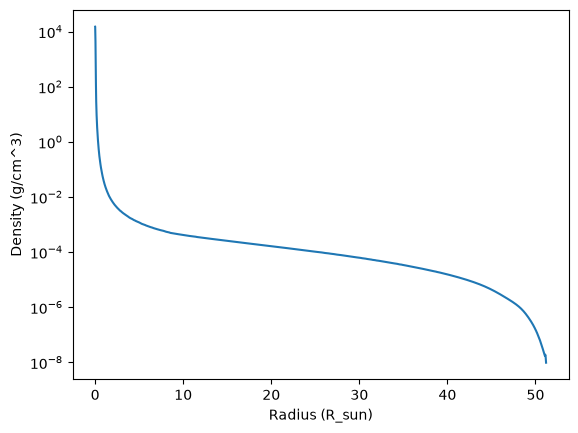

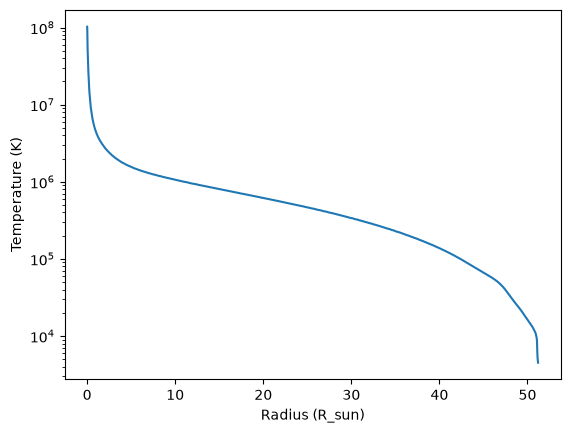

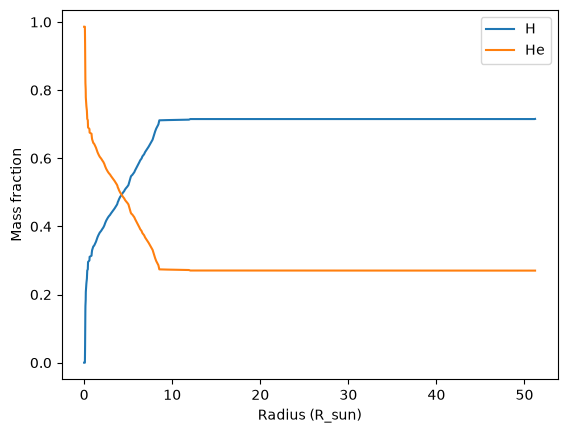

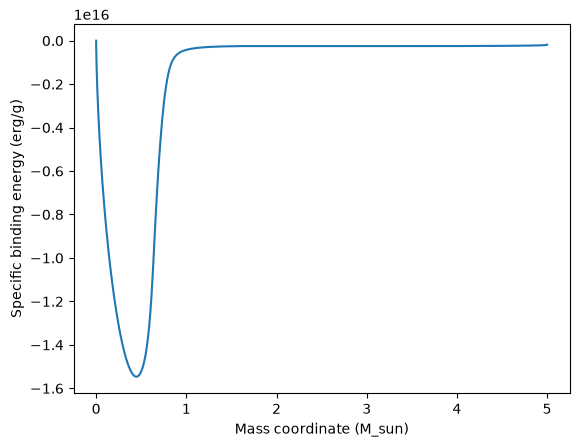

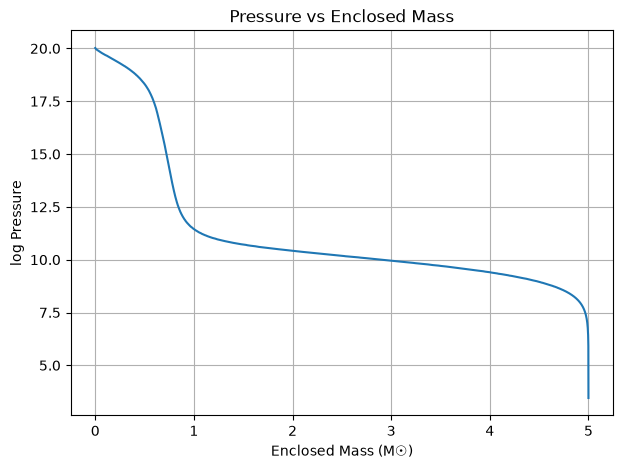

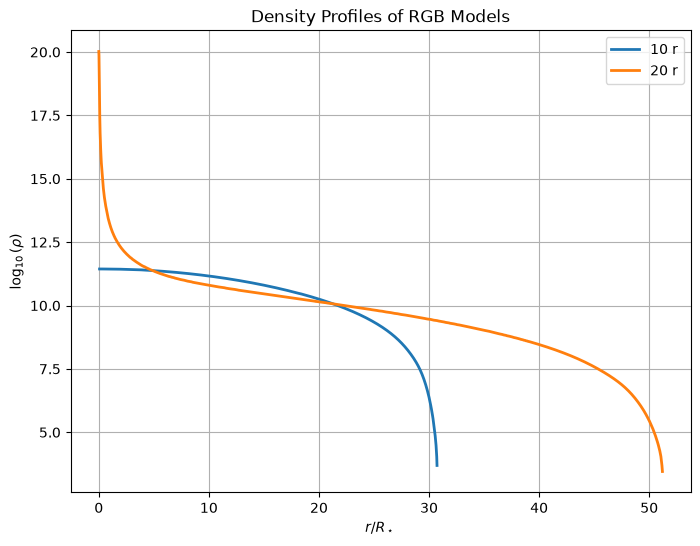

10 r
Max radius: 30.723575469560924
                                       1                                      560                  5.0000000000000000E+000                  1.4200000000000001E-002                  1.0000000000000001E-005                  1.0000000000000001E-005                  4.7132079113194113E+003                  4.1966580265503802E+002                  3.0723575469560938E+001                 -8.9837990471332905E+000                  7.1550000000000014E-001                  2.8765360029938303E-005                  2.7027123463997010E-001                  2.4179364918100769E-003                  7.1452936113231317E-004                  6.6425538704879576E-003                  1.3664100224769805E-003                  5.0000000000000000E+000                  0.0000000000000000E+000                  3.5774999999999966E+000                  1.4382680014969149E-004                  1.3513561731998496E+000                  1.2089682459050385E-002                  3.57

In [10]:
import matplotlib.pyplot as plt
import numpy as np

radius = 10**profile["logR"]   # radius in solar radii
rho = 10**profile["logRho"]    # density in g/cm^3

plt.plot(radius, rho)
plt.yscale("log")
plt.xlabel("Radius (R_sun)")
plt.ylabel("Density (g/cm^3)")
plt.show()

T = 10**profile["logT"]

plt.plot(radius, T)
plt.yscale("log")
plt.xlabel("Radius (R_sun)")
plt.ylabel("Temperature (K)")
plt.show()

plt.plot(radius, profile["x_mass_fraction_H"], label="H")
plt.plot(radius, profile["y_mass_fraction_He"], label="He")

plt.xlabel("Radius (R_sun)")
plt.ylabel("Mass fraction")
plt.legend()
plt.show()

G = 6.6743e-8
M = profile["mass"] * 1.9885e33
R = 10**profile["logR"] * 6.957e10

binding_energy = -G*M/R

plt.plot(profile["mass"], binding_energy)

plt.xlabel("Mass coordinate (M_sun)")
plt.ylabel("Specific binding energy (erg/g)")

plt.show()

mass = profile["mass"]

plt.figure(figsize=(7,5))
plt.plot(mass, profile["logP"])
plt.xlabel("Enclosed Mass (M☉)")
plt.ylabel("log Pressure")
plt.title("Pressure vs Enclosed Mass")
plt.grid(True)
plt.show()

from pathlib import Path

ROOT = Path.home() / "mesa_tutorial" / "results" / "mams_profiles"

models = [
    ("10 r", ROOT / "RGB5Msun_Z0p0142_logR1p0" / "RGB5Msun_Z0p0142_logR1p0.profile"),
    ("20 r", ROOT / "RGB5Msun_Z0p0142" / "RGB5Msun_Z0p0142.profile"),
]

plt.figure(figsize=(8,6))

for label, file in models:

    d = np.genfromtxt(file, names=True, skip_header=5)

    # Radius normalized to the stellar radius
    r = 10**d["logR"]

    plt.plot(r, d["logP"], lw=2, label=label)

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$\log_{10}(\rho)$")
plt.title(r"Density Profiles of RGB Models")
plt.legend()
plt.grid(True)
plt.show()

for label, file in models:
    d = np.genfromtxt(file, names=True, skip_header=5)

    print(label)
    print("Max radius:", np.max(10**d["logR"]))

    with open(file) as f:
        f.readline()
        f.readline()
        print(f.readline())   # header values
    print("-"*60)

In [13]:
for label, file in models:
    with open(file) as f:
        lines = f.readlines()

    print(label)
    print(lines[2])      # header values
    print(lines[5])      # first zone
    print()

10 r
                                       1                                      560                  5.0000000000000000E+000                  1.4200000000000001E-002                  1.0000000000000001E-005                  1.0000000000000001E-005                  4.7132079113194113E+003                  4.1966580265503802E+002                  3.0723575469560938E+001                 -8.9837990471332905E+000                  7.1550000000000014E-001                  2.8765360029938303E-005                  2.7027123463997010E-001                  2.4179364918100769E-003                  7.1452936113231317E-004                  6.6425538704879576E-003                  1.3664100224769805E-003                  5.0000000000000000E+000                  0.0000000000000000E+000                  3.5774999999999966E+000                  1.4382680014969149E-004                  1.3513561731998496E+000                  1.2089682459050385E-002                  3.5726468056615644E-003            

In [8]:
import numpy as np

history_file = "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB5Msun_Z0p0142_logR1p7/LOGS/history.data"

h = np.genfromtxt(history_file, names=True, skip_header=5)

R = 10**h["log_R"]

for target in [31, 32, 35, 40, 45, 50]:
    i = np.argmin(np.abs(R - target))

    print(
        f"Target R = {target:.1f} Rsun -> "
        f"model = {int(h['model_number'][i])}, "
        f"R = {R[i]:.3f} Rsun, "
        f"age = {h['star_age'][i]:.3e} yr, "
        f"XHc = {h['center_h1'][i]:.4f}"
    )

Target R = 31.0 Rsun -> model = 1, R = 30.724 Rsun, age = 1.000e-05 yr, XHc = 0.7155
Target R = 32.0 Rsun -> model = 1, R = 30.724 Rsun, age = 1.000e-05 yr, XHc = 0.7155
Target R = 35.0 Rsun -> model = 1, R = 30.724 Rsun, age = 1.000e-05 yr, XHc = 0.7155
Target R = 40.0 Rsun -> model = 1, R = 30.724 Rsun, age = 1.000e-05 yr, XHc = 0.7155
Target R = 45.0 Rsun -> model = 423, R = 51.201 Rsun, age = 8.431e+07 yr, XHc = 0.0000
Target R = 50.0 Rsun -> model = 423, R = 51.201 Rsun, age = 8.431e+07 yr, XHc = 0.0000


In [10]:
R = 10**h["log_R"]

for i in range(len(h)):
    print(
        f"model={int(h['model_number'][i]):4d}, "
        f"age={h['star_age'][i]:.4e} yr, "
        f"R={R[i]:.6f} Rsun, "
        f"XHc={h['center_h1'][i]:.6f}"
    )

for i in range(0, len(h), 20):
    print(
        f"model={int(h['model_number'][i]):4d}, "
        f"age={h['star_age'][i]:.4e} yr, "
        f"R={R[i]:.3f} Rsun, "
        f"XHc={h['center_h1'][i]:.4f}"
    )

model=   1, age=1.0000e-05 yr, R=30.723575 Rsun, XHc=0.715500
model= 423, age=8.4309e+07 yr, R=51.200794 Rsun, XHc=0.000000
model=   1, age=1.0000e-05 yr, R=30.724 Rsun, XHc=0.7155
